# Fake Job Posting Detection

Build a machine learning system to classify job postings as **FAKE** or **REAL**.

**Pipeline:** Collect Data → Explore & Clean → Text Preprocess → Vectorize (TF-IDF) → Train Multiple Models → Evaluate & Compare → Predict Fake or Real

Dataset: `fake_job_postings.csv` (17,880 job postings, target column `fraudulent`)


## Step 1: Understand the Problem

**Goal:** Classify job postings as FAKE (1) or REAL (0) based on their text and metadata.

**Evaluation metrics:** Accuracy, Precision, Recall, F1-score, ROC-AUC — since fake postings are rare, accuracy alone is misleading, so we look at all of them.


In [2]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 100)

RANDOM_STATE = 42


[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1028)>
[nltk_data] Error loading wordnet: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1028)>
[nltk_data] Error loading omw-1.4: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1028)>


## Step 2: Collect the Dataset

Loading the provided dataset.


In [3]:
df = pd.read_csv('fake_job_postings.csv')
print("Shape:", df.shape)
df.head(3)


Shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu...",Experience with content management systems a major plus (any blogging counts!)Familiar with the ...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Secon...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience work...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies across the Private ...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assis...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activi...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


## Step 3: Explore the Data (EDA)

Check shape, columns, data types, missing values, and the target distribution.


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [5]:
print("Missing values per column:\n")
print(df.isnull().sum().sort_values(ascending=False))


Missing values per column:

salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
title                      0
fraudulent                 0
dtype: int64


fraudulent
0    17014
1      866
Name: count, dtype: int64
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64 %


/var/folders/qc/r0mz5tr11tlckbpm1tnmybv00000gn/T/ipykernel_8965/1689889422.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='fraudulent', data=df, palette=['#4C72B0', '#C44E52'])


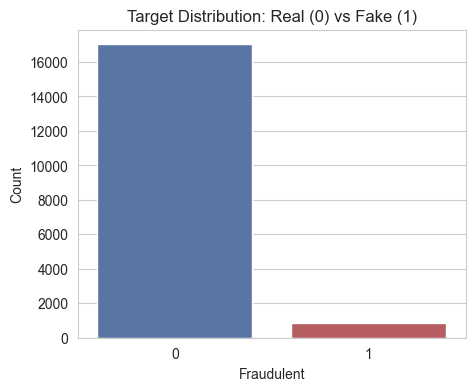

In [6]:
# Target distribution — this dataset is highly imbalanced
target_counts = df['fraudulent'].value_counts()
print(target_counts)
print(df['fraudulent'].value_counts(normalize=True).round(4) * 100, "%")

plt.figure(figsize=(5,4))
sns.countplot(x='fraudulent', data=df, palette=['#4C72B0', '#C44E52'])
plt.title('Target Distribution: Real (0) vs Fake (1)')
plt.xlabel('Fraudulent')
plt.ylabel('Count')
plt.show()


In [7]:
# Note the imbalance: fake postings are a small minority of the data.
fake_pct = df['fraudulent'].mean() * 100
print(f"Only {fake_pct:.2f}% of postings are fake.")
print("This means: (1) accuracy alone will be misleading, and")
print("(2) we should use class_weight='balanced' where possible and")
print("    focus on precision/recall/F1/ROC-AUC to evaluate models.")


Only 4.84% of postings are fake.
This means: (1) accuracy alone will be misleading, and
(2) we should use class_weight='balanced' where possible and
    focus on precision/recall/F1/ROC-AUC to evaluate models.


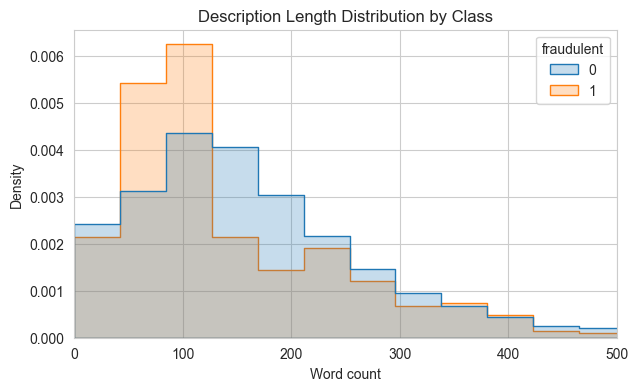

In [8]:
# Text length distribution (description length) by class
df['description'] = df['description'].fillna('')
df['desc_len'] = df['description'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(7,4))
sns.histplot(data=df, x='desc_len', hue='fraudulent', bins=50, kde=False,
             element='step', stat='density', common_norm=False)
plt.xlim(0, 500)
plt.title('Description Length Distribution by Class')
plt.xlabel('Word count')
plt.show()


## Step 4: Preprocess the Data

- Handle missing values (most text fields have NaNs — fill with empty string).
- Combine relevant text fields into a single field for modeling.
- Drop columns that aren't useful signal for a first pass (job_id, department, salary_range have huge missingness).


In [9]:
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for c in text_cols:
    df[c] = df[c].fillna('')

# Combine text fields into one — this is the "title + description" step from Step 6 (Feature Engineering)
df['full_text'] = (df['title'] + ' ' + df['company_profile'] + ' ' +
                    df['description'] + ' ' + df['requirements'] + ' ' + df['benefits'])

# Drop duplicates on the combined text
before = df.shape[0]
df = df.drop_duplicates(subset='full_text').reset_index(drop=True)
print(f"Dropped {before - df.shape[0]} duplicate rows")
print("New shape:", df.shape)


Dropped 1814 duplicate rows
New shape: (16066, 20)


## Step 5: Text Preprocessing (Important)

- Lowercase text
- Remove special characters, numbers, punctuation, URLs
- Remove stopwords
- Lemmatization


In [10]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)          # remove URLs
    text = re.sub(r'[^a-z\s]', ' ', text)                  # remove numbers/punctuation/special chars
    text = re.sub(r'\s+', ' ', text).strip()               # collapse whitespace
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words]    # remove stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]      # lemmatization
    return ' '.join(tokens)

# Demonstrate the cleaning pipeline on an example, like the guide's "Text Preprocessing Example"
sample = "We are looking for an experienced Developer!!! Salary 10000$ Apply now @ www.fakejob.com"
print("Original:        ", sample)
print("After full clean:", clean_text(sample))


Original:         We are looking for an experienced Developer!!! Salary 10000$ Apply now @ www.fakejob.com
After full clean: looking experienced developer salary apply


In [11]:
%%time
df['clean_text'] = df['full_text'].apply(clean_text)
df[['full_text', 'clean_text']].head(3)


CPU times: user 7.17 s, sys: 143 ms, total: 7.31 s
Wall time: 7.57 s


,full_text,clean_text
0,"Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site...",marketing intern food created groundbreaking award winning cooking site support connect celebrat...
1,"Customer Service - Cloud Video Production 90 Seconds, the worlds Cloud Video Production Service....",customer service cloud video production second world cloud video production service second world...
2,Commissioning Machinery Assistant (CMA) Valor Services provides Workforce Solutions that meet th...,commissioning machinery assistant cma valor service provides workforce solution meet need compan...


## Step 6: Feature Engineering

Convert cleaned text into numeric features using **TF-IDF**.


In [12]:
X_text = df['clean_text']
y = df['fraudulent']

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)


## Step 7: Split the Data

80% train / 20% test, stratified on the target to preserve the class ratio in both splits.


In [13]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train fraud rate: %.2f%%" % (y_train.mean() * 100))
print("Test fraud rate:  %.2f%%" % (y_test.mean() * 100))


Train shape: (12852, 5000)
Test shape: (3214, 5000)
Train fraud rate: 4.47%
Test fraud rate:  4.48%


## Step 8: Build Models

Train multiple algorithms: Logistic Regression, Naive Bayes, Decision Tree, Random Forest, SVM.
Where supported, `class_weight='balanced'` is used to counter the class imbalance.
SVM uses a linear kernel (`LinearSVC`, calibrated for probability outputs) since it scales far better than kernel `SVC` on high-dimensional TF-IDF text data.


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Naive Bayes': MultinomialNB(),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'SVM': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=2000), cv=3
    ),
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"Trained: {name}")


Trained: Logistic Regression
Trained: Naive Bayes


## Step 9: Evaluate Models

Don't rely only on accuracy — compare Accuracy, Precision, Recall, F1-score, and ROC-AUC across all models.


In [ ]:
results = []
roc_data = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        'Model': name, 'Accuracy': acc, 'Precision': prec,
        'Recall': rec, 'F1-score': f1, 'ROC-AUC': roc_auc
    })
    roc_data[name] = (y_test, y_proba)

results_df = pd.DataFrame(results).sort_values('F1-score', ascending=False).reset_index(drop=True)
results_df.round(3)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.983,0.894,0.701,0.786,0.955
1,Logistic Regression,0.956,0.504,0.799,0.618,0.957
2,Random Forest,0.974,0.942,0.451,0.610,0.969
3,Decision Tree,0.948,0.435,0.507,0.468,0.738
4,Naive Bayes,0.965,0.917,0.229,0.367,0.900


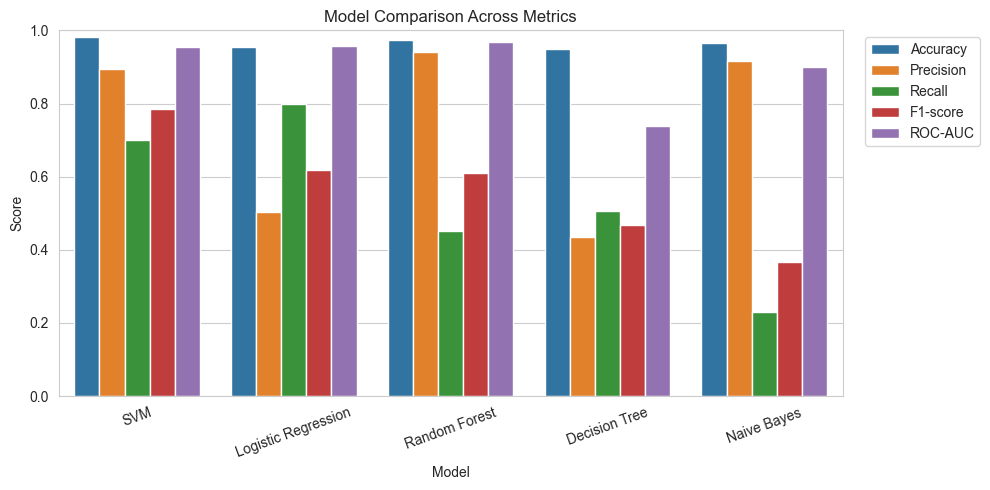

In [ ]:
# Visual comparison of models across metrics
results_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10,5))
sns.barplot(data=results_melted, x='Model', y='Score', hue='Metric')
plt.title('Model Comparison Across Metrics')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
# Pick the best model by F1-score (good default for imbalanced classification)
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print("Best model:", best_model_name)

y_pred_best = best_model.predict(X_test)
print(classification_report(y_test, y_pred_best, target_names=['Real', 'Fake']))


Best model: SVM
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3070
        Fake       0.89      0.70      0.79       144

    accuracy                           0.98      3214
   macro avg       0.94      0.85      0.89      3214
weighted avg       0.98      0.98      0.98      3214



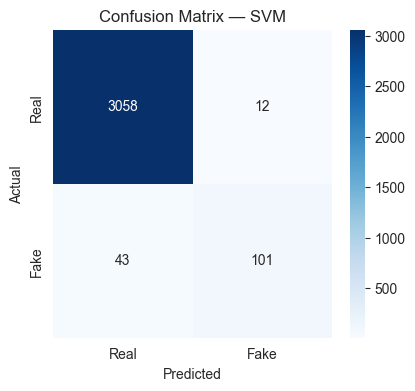

In [ ]:
# Confusion matrix for the best model
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(4.5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title(f'Confusion Matrix — {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


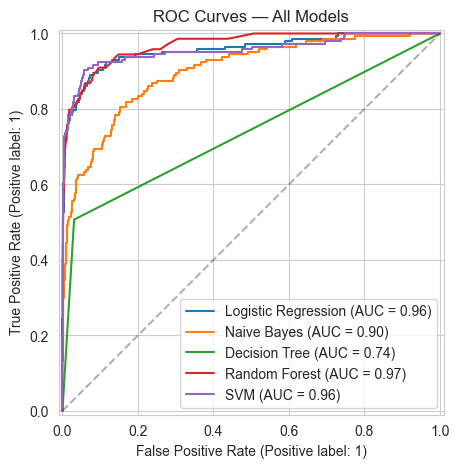

In [ ]:
# ROC curves for all models
plt.figure(figsize=(6,5))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
    RocCurveDisplay.from_predictions(y_test, y_proba, name=name, ax=plt.gca())
plt.plot([0,1],[0,1],'k--', alpha=0.3)
plt.title('ROC Curves — All Models')
plt.show()


## Step 10: Deploy Prediction System

A simple function that takes a new job posting's text and predicts Fake or Real using the best model, with a confidence score.


In [ ]:
def predict_job_posting(title='', company_profile='', description='', requirements='', benefits=''):
    """Predict whether a job posting is FAKE or REAL."""
    combined = f"{title} {company_profile} {description} {requirements} {benefits}"
    cleaned = clean_text(combined)
    vec = tfidf.transform([cleaned])

    pred = best_model.predict(vec)[0]
    if hasattr(best_model, "predict_proba"):
        proba = best_model.predict_proba(vec)[0]
        confidence = proba[pred]
    else:
        confidence = None

    label = "FAKE JOB POSTING" if pred == 1 else "REAL JOB POSTING"
    print(f"Prediction: {label}")
    if confidence is not None:
        print(f"Confidence: {confidence*100:.1f}%")
    if pred == 1:
        print("This posting looks suspicious. Be careful!")
    return label, confidence

# Example, similar to the guide's demo
predict_job_posting(
    description="Urgent opening!!! Earn $5000/week. Work from home, no experience needed. Send your resume now..."
)


Prediction: FAKE JOB POSTING
Confidence: 80.0%
This posting looks suspicious. Be careful!


('FAKE JOB POSTING', np.float64(0.7998667225096608))

In [ ]:
# Try it on a normal-looking posting too
predict_job_posting(
    title="Software Engineer",
    company_profile="We are an established fintech company based in New York.",
    description="We are looking for a backend engineer with 3+ years of experience in Python and distributed systems.",
    requirements="Bachelor's degree in Computer Science, experience with AWS."
)


Prediction: REAL JOB POSTING
Confidence: 99.6%


('REAL JOB POSTING', np.float64(0.9961608298678905))

## Limitations

- **Class imbalance:** only ~5% of postings are fake — consider techniques like SMOTE, class-weighted thresholds, or collecting more fake examples.
- **Generalization:** this model is trained on one dataset's writing style/era; scam tactics evolve, so it should be retrained periodically on fresh data.
- **Features not yet used:** `location`, `employment_type`, `required_experience`, `required_education`, `industry`, `telecommuting`, `has_company_logo`, `has_questions` could be added as additional (non-text) features to improve performance.
- **Ethical use:** false positives could unfairly flag a legitimate small company's posting as fake — this should support human review, not fully automate rejection of listings.
